# Notebook 4: Solutions to the exercises

Model solutions for instructors and self-learners. Try the exercises in `notebooks/04_deep_learning_reconstruction.ipynb` first.

## Setup (same as Notebook 4)

In [1]:
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from skimage.data import shepp_logan_phantom
from skimage.transform import resize

plt.rcParams["figure.dpi"] = 100
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # line colors, always used in this order

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print(f"Using {device}." + ("" if device.type == "cuda" else
      "  Training will take about 10 minutes in total. For a faster run: Runtime > Change runtime type > T4 GPU."))

Using cpu.  Training will take about 10 minutes in total. For a faster run: Runtime > Change runtime type > T4 GPU.


In [2]:
# From Notebooks 1-3 (now working on stacks of images too)
def fft2c(image):
    """Centered, orthonormal 2D FFT over the last two axes: image(s) -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image, axes=(-2, -1)), norm="ortho"), axes=(-2, -1))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT over the last two axes: k-space -> image(s)."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace, axes=(-2, -1)), norm="ortho"), axes=(-2, -1))


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.set_title(title)
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def nrmse(recon, reference):
    """Normalized root-mean-square error: 0 is perfect, 1 is as large as the image itself."""
    return np.linalg.norm(recon - reference) / np.linalg.norm(reference)


def tidy(ax):
    """Quiet grid and axes for line plots."""
    ax.grid(alpha=0.25, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)


def variable_density_lines(N, R, center_fraction=0.08, decay=3, seed=0):
    """N // R lines: a fully sampled center, the rest random and more likely near the center."""
    rng = np.random.default_rng(seed)
    n_total = N // R
    n_center = int(round(N * center_fraction))
    lines = np.zeros(N, dtype=bool)
    lines[N // 2 - n_center // 2 : N // 2 - n_center // 2 + n_center] = True
    candidates = np.flatnonzero(~lines)
    distance = np.abs(candidates - N // 2) / (N / 2)
    probability = (1 - distance) ** decay + 1e-6
    lines[rng.choice(candidates, size=n_total - n_center, replace=False,
                     p=probability / probability.sum())] = True
    return lines


# Compressed sensing from Notebook 3, for comparison
SQRT2 = np.sqrt(2)


def haar2(x, levels=4):
    c = x.astype(complex).copy()
    n = c.shape[0]
    for _ in range(levels):
        a = c[:n, :n]
        a = np.hstack([(a[:, 0::2] + a[:, 1::2]) / SQRT2, (a[:, 0::2] - a[:, 1::2]) / SQRT2])
        a = np.vstack([(a[0::2, :] + a[1::2, :]) / SQRT2, (a[0::2, :] - a[1::2, :]) / SQRT2])
        c[:n, :n] = a
        n //= 2
    return c


def ihaar2(c, levels=4):
    x = c.copy()
    n = x.shape[0] // 2 ** (levels - 1)
    for _ in range(levels):
        a = x[:n, :n]
        h = n // 2
        b = np.empty_like(a)
        b[0::2, :] = (a[:h, :] + a[h:, :]) / SQRT2
        b[1::2, :] = (a[:h, :] - a[h:, :]) / SQRT2
        a2 = np.empty_like(a)
        a2[:, 0::2] = (b[:, :h] + b[:, h:]) / SQRT2
        a2[:, 1::2] = (b[:, :h] - b[:, h:]) / SQRT2
        x[:n, :n] = a2
        n *= 2
    return x


def soft_threshold(c, lam):
    magnitude = np.abs(c)
    return c * np.maximum(magnitude - lam, 0) / np.maximum(magnitude, 1e-12)


def cs_reconstruct(kspace_measured, lines, lam=0.01, n_iter=200, levels=4):
    n = kspace_measured.shape[0]
    coarse = np.zeros((n, n), dtype=bool)
    coarse[: n // 2**levels, : n // 2**levels] = True
    x = ifft2c(kspace_measured)
    for _ in range(n_iter):
        k = np.where(lines[:, None], kspace_measured, fft2c(x))
        x = ifft2c(k)
        w = haar2(x, levels)
        x = ihaar2(np.where(coarse, w, soft_threshold(w, lam)), levels)
    return x

In [3]:
def random_phantom(rng, N=128, oversample=2):
    """A random head-like phantom: a bright skull ring, a darker brain,
    4-8 internal structures and 1-3 small 'lesions'. Values between 0 and 1."""
    M = N * oversample                                  # draw at higher resolution, then average down
    y, x = np.mgrid[-1:1:M * 1j, -1:1:M * 1j]
    img = np.zeros((M, M))

    def ellipse(cx, cy, a, b, angle, value):
        c, s = np.cos(angle), np.sin(angle)
        xr = (x - cx) * c + (y - cy) * s
        yr = -(x - cx) * s + (y - cy) * c
        img[(xr / a) ** 2 + (yr / b) ** 2 <= 1] += value

    def random_point_inside(spread):
        r, phi = rng.uniform(0, spread), rng.uniform(0, 2 * np.pi)
        return cx + r * (a - t) * 0.8 * np.cos(phi), cy + r * (b - t) * 0.8 * np.sin(phi)

    # head outline: skull ring around a darker brain
    cx, cy = rng.uniform(-0.05, 0.05, 2)
    a, b = rng.uniform(0.6, 0.75), rng.uniform(0.8, 0.92)
    angle = rng.uniform(-0.2, 0.2)
    t = rng.uniform(0.04, 0.07)                         # skull thickness
    ellipse(cx, cy, a, b, angle, 1.0)
    ellipse(cx, cy, a - t, b - t, angle, rng.uniform(0.15, 0.3) - 1.0)

    # internal structures of different sizes and brightness
    for _ in range(rng.integers(4, 9)):
        ex, ey = random_point_inside(0.6)
        size = rng.uniform(0.04, 0.25)
        ellipse(ex, ey, size * rng.uniform(0.4, 1.0), size, rng.uniform(0, np.pi), rng.uniform(-0.2, 0.25))

    # a few small bright or dark "lesions"
    for _ in range(rng.integers(1, 4)):
        ex, ey = random_point_inside(0.7)
        size = rng.uniform(0.015, 0.04)
        ellipse(ex, ey, size, size * rng.uniform(0.6, 1.0), rng.uniform(0, np.pi),
                rng.uniform(0.1, 0.3) * rng.choice([-1, 1]))

    img = np.clip(img, 0, 1)
    return img.reshape(N, oversample, N, oversample).mean(axis=(1, 3))

In [4]:
N, R = 128, 4
N_TRAIN, N_VAL, N_TEST = 1000, 100, 100

rng = np.random.default_rng(0)
start = time.time()
truth = np.stack([random_phantom(rng, N) for _ in range(N_TRAIN + N_VAL + N_TEST)])
print(f"Generated {len(truth)} phantoms in {time.time() - start:.0f} s")

lines = variable_density_lines(N, R)                    # one fixed sampling pattern, as on a scanner
measured = fft2c(truth) * lines[:, None]                # undersampled k-space (unmeasured lines = 0)
zero_filled = ifft2c(measured)                          # network input: complex zero-filled images

train, val, test = slice(0, N_TRAIN), slice(N_TRAIN, N_TRAIN + N_VAL), slice(N_TRAIN + N_VAL, None)

# An extra test image the networks never see in any form: the Shepp-Logan phantom
sl_truth = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)
sl_measured = fft2c(sl_truth) * lines[:, None]
sl_zero_filled = ifft2c(sl_measured)
print(f"{lines.sum()} of {N} lines measured (R = {R})")

Generated 1200 phantoms in 12 s


32 of 128 lines measured (R = 4)


In [5]:
def to_tensor(c):
    """Complex images (B, N, N) -> real tensor (B, 2, N, N): channel 0 = real part, channel 1 = imaginary part."""
    return torch.tensor(np.stack([c.real, c.imag], axis=1), dtype=torch.float32)


def to_complex(t):
    """Inverse of to_tensor: (B, 2, N, N) -> complex NumPy array (B, N, N)."""
    t = t.detach().cpu().numpy()
    return t[:, 0] + 1j * t[:, 1]


X = to_tensor(zero_filled)                               # network inputs
Y = to_tensor(truth.astype(complex))                     # targets: the true images (imaginary part 0)
K = torch.tensor(measured, dtype=torch.complex64)        # measured k-space, needed for data consistency
MASK = torch.tensor(lines[:, None], device=device)       # True on measured lines

print("inputs:", tuple(X.shape), " targets:", tuple(Y.shape))

inputs: (1200, 2, 128, 128)  targets: (1200, 2, 128, 128)


In [6]:
def conv_block(c_in, c_out):
    """Two 3x3 convolutions, each followed by ReLU."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    """A small U-Net that predicts a correction to the zero-filled image."""

    def __init__(self, channels=2, base=16):
        super().__init__()
        # encoder: features at 128, 64 and 32 pixels
        self.enc1 = conv_block(channels, base)
        self.enc2 = conv_block(base, 2 * base)
        self.enc3 = conv_block(2 * base, 4 * base)
        # bottleneck at 16 pixels
        self.bottom = conv_block(4 * base, 8 * base)
        # decoder: upsample, join with the matching encoder features (skip connection), convolve
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * base, 4 * base, 2, stride=2), conv_block(8 * base, 4 * base)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * base, 2 * base, 2, stride=2), conv_block(4 * base, 2 * base)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * base, base, 2, stride=2), conv_block(2 * base, base)
        self.out = nn.Conv2d(base, channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        e3 = self.enc3(F.max_pool2d(e2, 2))
        b = self.bottom(F.max_pool2d(e3, 2))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return x + self.out(d1)          # residual: input + learned correction


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

In [7]:
def run_model(model, x, k):
    """Run a model on a batch. Unrolled networks also need the measured k-space."""
    return model(x, k) if getattr(model, "uses_kspace", False) else model(x)


def train_model(model, epochs, batch_size=16, lr=1e-3, n_train=N_TRAIN, seed=0):
    """Train with the L1 loss and the Adam optimizer. Returns the loss history."""
    torch.manual_seed(seed)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    order = np.arange(n_train)
    history = {"train": [], "val": []}
    for epoch in range(epochs):
        start = time.time()
        model.train()
        np.random.default_rng(seed + epoch).shuffle(order)
        total = 0.0
        for i in range(0, n_train, batch_size):
            b = order[i : i + batch_size]
            x, y, k = X[b].to(device), Y[b].to(device), K[b].to(device)
            loss = F.l1_loss(run_model(model, x, k), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            val_loss = F.l1_loss(run_model(model, X[val].to(device), K[val].to(device)), Y[val].to(device)).item()
        history["train"].append(total / n_train)
        history["val"].append(val_loss)
        print(f"epoch {epoch + 1}/{epochs}: train loss {total / n_train:.4f}, "
              f"validation loss {val_loss:.4f}  ({time.time() - start:.0f} s)")
    return history


def predict(model, x_complex, k_measured):
    """Reconstruct magnitude images (B, N, N) from zero-filled complex images and measured k-space."""
    model.eval()
    with torch.no_grad():
        x = to_tensor(x_complex).to(device)
        k = torch.tensor(k_measured, dtype=torch.complex64).to(device)
        return np.abs(to_complex(run_model(model, x, k)))


def plot_history(history, title):
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    epochs = np.arange(1, len(history["train"]) + 1)
    ax.plot(epochs, history["train"], "o-", color=COLORS[0], linewidth=2, markersize=8, label="training images")
    ax.plot(epochs, history["val"], "o-", color=COLORS[1], linewidth=2, markersize=8, label="validation images")
    ax.set_xlabel("epoch")
    ax.set_ylabel("L1 loss")
    ax.set_title(title, loc="left")
    ax.set_xticks(epochs)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
    tidy(ax)
    plt.tight_layout()
    plt.show()


def load_pretrained(model, filename):
    """Download weights trained with this notebook's settings from the module's GitHub repository."""
    url = f"https://raw.githubusercontent.com/anupbagale/mri-recon-tutorial/main/weights/{filename}"
    urllib.request.urlretrieve(url, filename)
    model.load_state_dict(torch.load(filename, map_location=device))
    return model.to(device)

In [8]:
def tfft2c(x):
    """Centered, orthonormal 2D FFT in PyTorch (same as fft2c)."""
    return torch.fft.fftshift(torch.fft.fft2(torch.fft.ifftshift(x, dim=(-2, -1)), norm="ortho"), dim=(-2, -1))


def tifft2c(k):
    """Centered, orthonormal inverse 2D FFT in PyTorch (same as ifft2c)."""
    return torch.fft.fftshift(torch.fft.ifft2(torch.fft.ifftshift(k, dim=(-2, -1)), norm="ortho"), dim=(-2, -1))


def data_consistency(x, k_measured):
    """Put the measured k-space lines back, exactly as in Notebook 3 (step 1 of ISTA)."""
    image = torch.complex(x[:, 0], x[:, 1])
    k = torch.where(MASK, k_measured, tfft2c(image))
    image = tifft2c(k)
    return torch.stack([image.real, image.imag], dim=1)


class SmallCNN(nn.Module):
    """Five 3x3 convolutions that predict a correction to their input."""

    def __init__(self, channels=2, width=16, depth=5):
        super().__init__()
        layers = [nn.Conv2d(channels, width, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(width, channels, 3, padding=1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.net(x)


class UnrolledNet(nn.Module):
    """A 'learned ISTA': several rounds of (small CNN -> data consistency)."""
    uses_kspace = True

    def __init__(self, cascades=4):
        super().__init__()
        self.cnns = nn.ModuleList([SmallCNN() for _ in range(cascades)])

    def forward(self, x, k_measured):
        for cnn in self.cnns:
            x = cnn(x)                                  # learned step: make it look like a real image
            x = data_consistency(x, k_measured)         # fixed step: agree with the measurements
        return x

In [9]:
# use the Notebook 4 weights if they are in this session, otherwise download them
import os

def load_or_download(model, filename):
    if os.path.exists(filename):
        model.load_state_dict(torch.load(filename, map_location=device))
        return model.to(device)
    return load_pretrained(model, filename)

unet = load_or_download(UNet(), "unet_r4.pt")
unrolled = load_or_download(UnrolledNet(), "unrolled_r4.pt")

def mean_nrmse(recons, truths):
    return np.mean([nrmse(r, t) for r, t in zip(recons, truths)])

unet_test = predict(unet, zero_filled[test], measured[test])
print(f"U-Net test NRMSE: {mean_nrmse(unet_test, truth[test]):.3f}")

U-Net test NRMSE: 0.159


## Exercise 1: was the U-Net trained long enough?

epoch 1/6: train loss 0.0191, validation loss 0.0155  (43 s)


epoch 2/6: train loss 0.0142, validation loss 0.0136  (44 s)


epoch 3/6: train loss 0.0131, validation loss 0.0127  (44 s)


epoch 4/6: train loss 0.0121, validation loss 0.0113  (44 s)


epoch 5/6: train loss 0.0111, validation loss 0.0109  (43 s)


epoch 6/6: train loss 0.0105, validation loss 0.0097  (43 s)


                       test NRMSE  lesion contrast
true image                                    0.41
U-Net, 6 epochs             0.159             0.07
U-Net, 12 epochs            0.106             0.31


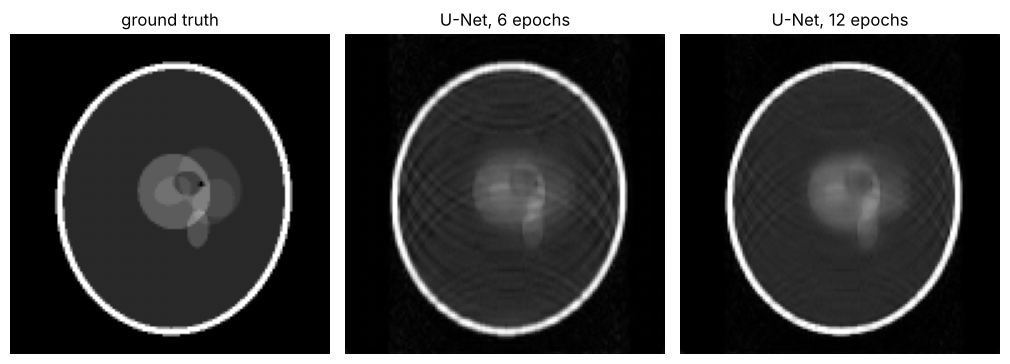

In [10]:
from scipy.ndimage import uniform_filter

def local_contrast(img, r, c, size=7):
    # how much darker pixel (r, c) is than the average of its size x size neighborhood
    return uniform_filter(img, size)[r, c] - img[r, c]

t = truth[test][0]
r, c = np.unravel_index(np.argmax((uniform_filter(t, 7) - t) * (t < 0.08)), t.shape)

import copy

before = unet_test
longer = copy.deepcopy(unet)                             # a copy, so the exercises below still use the original
more_history = train_model(longer, epochs=6, seed=1)     # continues from the trained weights
after = predict(longer, zero_filled[test], measured[test])

print(f"{'':<22}{'test NRMSE':>11}{'lesion contrast':>17}")
print(f"{'true image':<22}{'':>11}{local_contrast(t, r, c):>17.2f}")
print(f"{'U-Net, 6 epochs':<22}{mean_nrmse(before, truth[test]):>11.3f}{local_contrast(before[0], r, c):>17.2f}")
print(f"{'U-Net, 12 epochs':<22}{mean_nrmse(after, truth[test]):>11.3f}{local_contrast(after[0], r, c):>17.2f}")
show([t, before[0], after[0]], ["ground truth", "U-Net, 6 epochs", "U-Net, 12 epochs"], vmin=0, vmax=1)

Six more epochs make a large difference: the test error drops from about 0.16 to about 0.11, and the lesion contrast recovers from almost nothing to roughly three quarters of its true value, about as good as compressed sensing. The image still looks softer than the ground truth, but the streaks are fainter.

So the comparison in Section 7 was not entirely fair to the U-Net: it was simply undertrained. The lesson for evaluating any method, including in published papers: every method needs an equal chance. Tune λ for compressed sensing, train networks until the validation loss stops improving, and report how much effort went into each. A comparison against a weak baseline can make almost any new method look good.

## Exercise 2: data consistency after the fact

In [11]:
unet.eval()
with torch.no_grad():
    x = to_tensor(zero_filled[test]).to(device)
    k = torch.tensor(measured[test], dtype=torch.complex64).to(device)
    unet_dc = np.abs(to_complex(data_consistency(run_model(unet, x, k), k)))
unrolled_test = predict(unrolled, zero_filled[test], measured[test])

print(f"U-Net:                    {mean_nrmse(unet_test, truth[test]):.3f}")
print(f"U-Net + one DC step:      {mean_nrmse(unet_dc, truth[test]):.3f}")
print(f"unrolled network:         {mean_nrmse(unrolled_test, truth[test]):.3f}")

U-Net:                    0.159
U-Net + one DC step:      0.144
unrolled network:         0.052


One data consistency step after the U-Net helps a little, because the measured lines are now exactly right. But it is nowhere near the unrolled network. The U-Net was never trained to work *together* with data consistency, so its output disagrees with the measured lines. Putting them back fixes the measured part of k-space but cannot fix what the U-Net got wrong in the unmeasured part. The unrolled network learns, during training, to produce images that only need small corrections from each data consistency step. Building data consistency into the network is much more powerful than adding it afterwards.

## Exercise 3: what did the network learn?

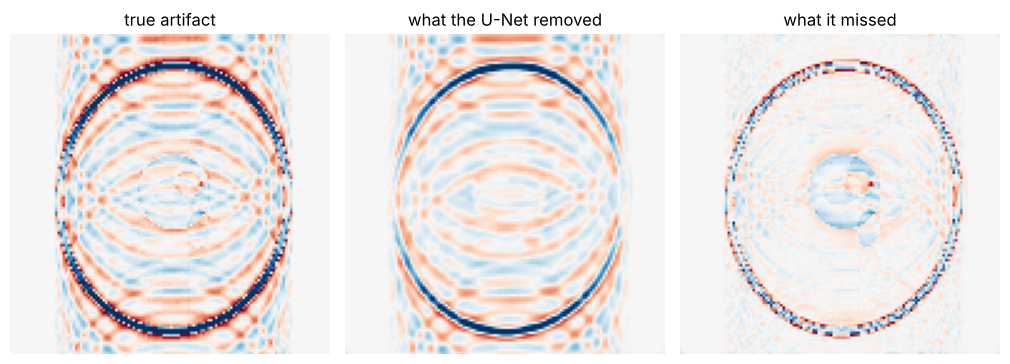

The U-Net removed 51% of the artifact (by norm).


In [12]:
i = 0
zf_i = zero_filled[test][i]
unet.eval()
with torch.no_grad():
    out_i = to_complex(unet(to_tensor(zf_i[None]).to(device)))[0]

true_artifact = (zf_i - truth[test][i]).real
predicted_correction = (zf_i - out_i).real    # sign flipped so both show "what is wrong with the input"

show([true_artifact, predicted_correction, true_artifact - predicted_correction],
     ["true artifact", "what the U-Net removed", "what it missed"], cmap="RdBu_r", vmin=-0.3, vmax=0.3)
print(f"The U-Net removed {1 - np.linalg.norm(true_artifact - predicted_correction) / np.linalg.norm(true_artifact):.0%} "
      f"of the artifact (by norm).")

The U-Net removed about half of the artifact, and specifically its smooth, wave-like streak pattern, which is the same in every image because the mask is fixed. What it missed is the fine, sharp detail: the exact skull edge, the edges of the internal structures and the small lesion (the red dot). Those differ from image to image and are hard to guess from a zero-filled image alone. The unrolled network gets them right because data consistency keeps feeding the measured high-frequency lines back in.

## Exercise 4: speed in practice

In [13]:
# times per 128 x 128 image, measured on this machine (re-measure on yours)
x = zero_filled[test][:1]; k = measured[test][:1]
timings = {}
start = time.time(); [np.abs(ifft2c(k)) for _ in range(20)]; timings["zero-filled"] = (time.time() - start) / 20
start = time.time(); [cs_reconstruct(k[0], lines) for _ in range(3)]; timings["compressed sensing"] = (time.time() - start) / 3
for name, model in [("U-Net", unet), ("unrolled network", unrolled)]:
    predict(model, x, k)  # warm-up
    start = time.time(); [predict(model, x, k) for _ in range(20)]; timings[name] = (time.time() - start) / 20

print(f"{'method':<20}{'1 slice':>10}{'30 slices':>12}{'150 slices':>12}{'150 at 256x256':>16}")
for name, t in timings.items():
    print(f"{name:<20}{t:>9.3f}s{30 * t:>11.1f}s{150 * t:>11.1f}s{150 * t * 4:>15.1f}s")

method                 1 slice   30 slices  150 slices  150 at 256x256
zero-filled             0.000s        0.0s        0.1s            0.3s
compressed sensing      0.369s       11.1s       55.3s          221.3s
U-Net                   0.021s        0.6s        3.2s           12.8s
unrolled network        0.020s        0.6s        3.0s           12.2s


Four times as many pixels means roughly four times the work (a little more for the FFTs). Compressed sensing quickly reaches minutes for a full exam, and real scans add multiple receiver coils, which multiplies the cost again. A trained network stays at seconds. Speed, not only image quality, is a main reason deep learning reconstruction spread so quickly into clinical scanners. Remember that training time is not included: it is paid once, before the first patient.